### model of dome emplacement for the intermediate and silicic domes

Here is one end-member model of silicic domes. 

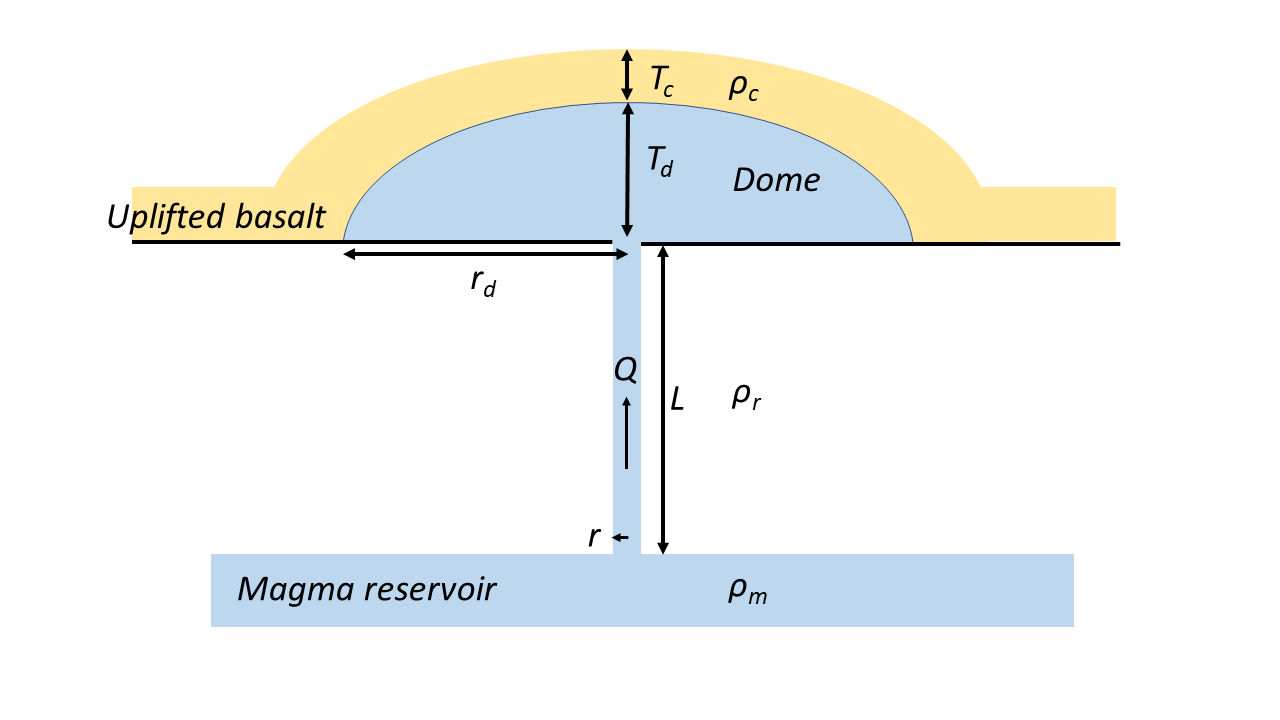

From basic Pouiselle flow in a conduit, volumetric flow is driven by the pressure gradient
$$Q = - \frac{\pi r^4}{8 \mu} \frac{dp}{dx} $$

For buoyant rise, the pressure gradient along the conduit is only the pressure available because of the density difference between magma (lighter)and host rock (heavier):

$$\frac{dp}{dx} = -\frac{(\rho_r - \rho_m) g L}{L}$$

where $L$ is the length of the conduit

$$Q = \frac{\pi r^4 (\rho_r - \rho_m) g}{8 \mu}$$


where:

$r$ = conduit radius

$L$ = conduit length (in this case seems to go from the midcrustal sill to the surface)

$\mu$ is magma viscosity

$\Delta \rho$ is the density difference between the magma and the rock. $\rho_m$ is the density of the magma; $\rho_r$ is the density of the rock. Note that density differences in the crust (layers) may mean that the integrated density must be determined. $\Delta \rho = \rho_r - \rho_m > 0$ for buoyant rise.

$g$ is gravitational acceleration

In this model the magma reservoir pressure is equal to lithostatic pressure: there is no magma overpressure related to bubble nucleation in the magma.


In [2]:
import numpy as np
def laminar_flow_pipe(g, mu,r,rho_m, rho_r):
    q = np.pi*r**4*(rho_r - rho_m)*g/(8*mu)
    return q

g = 10 #m/s2
mu = 1000000 #pa s
r = 10 #m

rho_m = 2400 #density of magma
rho_r = 2500 #density of rock

print ("flow rate, q = ", laminar_flow_pipe(g, mu,r,rho_m, rho_r), "m^3/s")

flow rate, q =  3.926990816987241 m^3/s


If one assumes a high viscosity, high yield strength magma (1 MPa s in this example) and a relatively low densty contrast, volumetric flow rate matches observed dome effusion rates.

### For an "eruption" beneath a basalt cap
If the dome is endogenous and uplifts a basaltic cap, the pressure gradient changes because of the weight of the overlying basalt cap.


$$Q = \frac{\pi r^4}{8 \mu} \left [ (\rho_r - \rho_m) g - \frac{\rho_c g T_c}{L}\right ] $$

Note the impact of the basalt cap on the flow rate depends on the length of the conduit (depth of the magma reservoir). This makes sense, a long conduit means the cap causes a small change in the pressure gradient. There is positive flow (eruption) only if:

$$(\rho_r - \rho_m)  > \frac{\rho_c  T_c}{L} $$

Note: I assume in the following script the density of the cap is about the same as the density of the magma, but this does not have to be the case.

In [3]:
import numpy as np
def laminar_flow_pipe_cap(g, mu,r,rho_m, rho_r, thick, conduit_length):
    q = np.pi*r**4/(8*mu)*((rho_r - rho_m)*g - rho_m*g*thick/conduit_length)
    return q

g = 10 #m/s2
mu = 1000000 #pa s
r = 10 #m

rho_m = 2400 #density of magma
rho_r = 2500 #density of rock

thick = 300
conduit_length = 10000
print ("flow rate, q = ", laminar_flow_pipe_cap(g, mu,r,rho_m, rho_r, thick, conduit_length), "m^3/s")

flow rate, q =  1.0995574287564276 m^3/s


All other things being equal, the work of lifting 300 m of basalt cap reduces the maximum flow rate to about one quarter of its value if the dome erupts at the surface.

#### Adding the height of the dome
The height of the dome increases as magma continues to erupt from the conduit, under the basalt cap or not. This adds an additional static load to the conduit, and reduces the flow rate as the dome builds height.


$$Q = \frac{\pi r^4}{8 \mu} \left [ (\rho_r - \rho_m) g - \frac{\rho_c g T_c}{L} - \frac{\rho_m g T_d}{L}\right ] $$

where $T_d$ is the thickness (height) of the dome. That is, the eruption starts at its maximum flow rate ($T_d = 0$) and decreases in volumetric flow rate as height increases. The eruption stops when:

$$(\rho_r - \rho_m)  = \frac{\rho_c  T_c}{L} +  \frac{\rho_m  T_d}{L}$$

$$ T_d = \frac{(\rho_r - \rho_m) L  - \rho_c  T_c}{\rho_m} $$

which suggests the final dome height (plus previous rocks displaced in the basalt cap) is only a function of density contrasts, thickness of the basalt cap and depth of the source, if the magma is rising buoyantly and there is no magma overpressure.

Yield strength of the dome controls the change in radius of the dome with change in height. Yield strength, $\tau$, is orders of magnitude higher in intermediate and silicic domes than in basaltic magmas because of crystallization, which increases during the eruption or intrusion of the dome. Eventually, enough crystals form in the magma to create a continuous crystal phase that greatly increases the magma yield strength. Saar et al. (2001) found that yield strength rapidly increases with increasing crystal fraction, $\phi$ above the critical threshold at which a continuous phase forms ($\phi_c$). 

The variation in the height can give the expected dome radius:

$$r_d = \frac{\rho_m g T_d^2}{C^2 \tau} $$

where $C^2$ is a constant and $\tau$ is the yield strength (Wilson and Head, 2003).

Saar, M.O., Manga, M., Cashman, K.V. & Fremouw, S., 2001. Numerical
models of the onset of yield strength in crystal–melt suspensions, Earth
Planet. Sci. Lett., 187(3–4), 367–379.

Wilson, L. and Head, J.W., 2003. Lunar Gruithuisen and Mairan domes: Rheology and mode of emplacement. Journal of Geophysical Research: Planets, 108(E2).

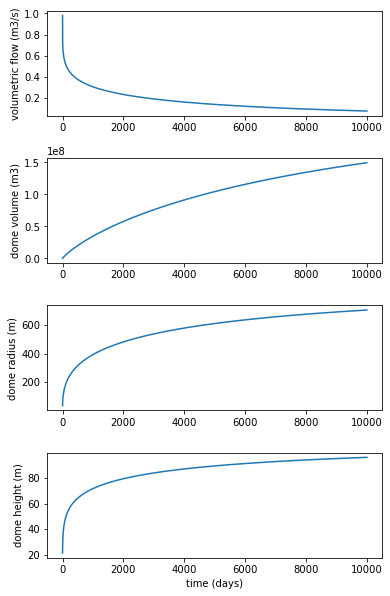

In [4]:
import numpy as np
import matplotlib.pyplot as plt
def laminar_flow_pipe_cap_dome(g, mu,r,rho_m, 
                               rho_r, rho_c, cap_thick, 
                               dome_thick, conduit_length):
    
    q = np.pi*r**4/(8*mu)*((rho_r - rho_m)*g 
                           - rho_c*g*cap_thick/conduit_length 
                           - rho_m*g*dome_thick/conduit_length)
    return q

g = 10 #m/s2
mu = 1000000 #pa s
r = 10 #m

rho_m = 2400 #density of magma
rho_r = 2500 #density of rock
rho_c = 2500 #density of cap

cap_thick = 300
conduit_length = 10000

c= 1.76 #constant for dome radius vs thickness
tau = 1000000 #dome yield strength

#initialize sets
vol = []
rad = []
ht = []
flow =[]
days = []
#initial conditions
dome_thickness = 0.0
eruption_time = 0
volume = 0.0
for i in range(0,10000,1): #i is eruption time in days
    
    delta_t = 3600.0*24.0
    eruption_time += delta_t
    q = laminar_flow_pipe_cap_dome(g, mu,r,rho_m, rho_r, rho_c, cap_thick, dome_thickness, conduit_length)
    
    if q < 0.01:
        break
    volume += q*delta_t
    dome_radius = (rho_m*g*volume**2/(c**2*tau))**(1/5)
    dome_thickness = volume/(np.pi*dome_radius**2)
    eruption_time_days = eruption_time/(3600.0*24.0)
    
    vol.append(volume)
    rad.append(dome_radius)
    ht.append(dome_thickness)
    flow.append(q)
    days.append(eruption_time_days)

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1)

ax1.plot(days, flow, '-')
ax1.set_ylabel('volumetric flow (m3/s)')

ax2.plot(days, vol, '-')
ax2.set_ylabel('dome volume (m3)')

ax3.plot(days, rad, '-')
ax3.set_ylabel('dome radius (m)')

ax4.plot(days, ht, '-')
ax4.set_ylabel('dome height (m)')

ax4.set_xlabel('time (days)')

# set the spacing between subplots
plt.subplots_adjust(bottom=0.1, 
                    top=2, 
                    wspace=0.4, 
                    hspace=0.4)
plt.savefig('dome_growth2.pdf')
plt.show()

median radius =  1158.9739559344616


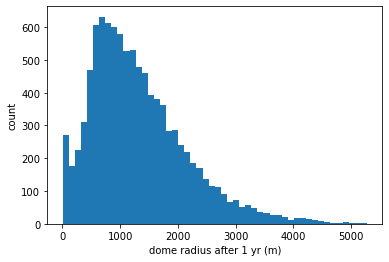

In [5]:
# randomly sample input variables to estimate radius of dome after 1 year

import numpy as np
import matplotlib.pyplot as plt
def laminar_flow_pipe_cap_dome(g, mu,r,rho_m, 
                               rho_r, rho_c, cap_thick, 
                               dome_thick, conduit_length):
    
    q = np.pi*r**4/(8*mu)*((rho_r - rho_m)*g 
                           - rho_c*g*cap_thick/conduit_length 
                           - rho_m*g*dome_thick/conduit_length)
    return q

g = 9.8 #m/s2
rad = []
for j in range (10000):
    mu = np.random.uniform(500000, 2500000)
    r = np.random.uniform(10,25) #m

    rho_m = np.random.uniform(2200, 2450)  #density of magma
    rho_r = 2500 #density of rock
    rho_c = 2400 #density of cap

    cap_thick = np.random.uniform(50,500) 
    conduit_length = np.random.uniform(10000, 20000)

    c= 1.76 #constant for dome radius vs thickness
    tau = mu #dome yield strength

    #initial conditions
    dome_thickness = 0.0
    eruption_time = 0
    volume = 0.0
    for i in range(0,365,1): #i is eruption time in days
        delta_t = 3600.0*24.0
        eruption_time += delta_t
        q = laminar_flow_pipe_cap_dome(g, mu,r,rho_m, rho_r, rho_c, cap_thick, dome_thickness, conduit_length)
    
        volume += q*delta_t
        dome_radius = (rho_m*g*volume**2/(c**2*tau))**(1/5)
        dome_thickness = volume/(np.pi*dome_radius**2)
        eruption_time_days = eruption_time/(3600.0*24.0)
    
    rad.append(dome_radius)
print("median radius = ", np.median(rad))
plt.hist(rad, bins=50)
plt.xlabel("dome radius after 1 yr (m)")
plt.ylabel ("count")
plt.savefig('radius_simulation.pdf')
plt.show()

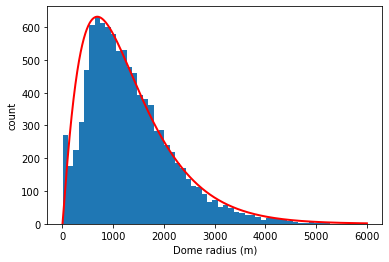

In [6]:
# fit a lognormal distribution to the simulation results
import scipy
import scipy.stats as stats


counts, bins, _ = plt.hist(rad, bins=50)

dist = stats.gamma(*stats.gamma.fit(rad, floc=0))
x = np.arange(1,6000)
y = dist.pdf(x)

# the pdf is normalized, so we need to scale it to match the histogram
y = y/y.max()
y = y*counts.max()


plt.plot(x,y,'r',linewidth=2)
plt.xlabel("Dome radius (m)")
plt.ylabel("count")
plt.savefig('radius_simulation_curvefit.pdf')
plt.show()

[9.99999353e-01 9.99997246e-01 9.99993578e-01 ... 9.02899587e-04
 9.01613021e-04 9.00328266e-04]


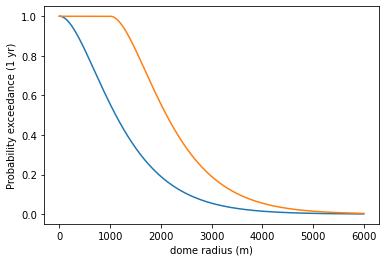

In [7]:
shape, loc, scale = scipy.stats.gamma.fit(rad, floc=0)
x = np.arange(1,6000)

adj_rad = []
adj_survivor = []
for i in range(len(x)):
    if (x[i] < 1000):
        adj_survivor.append(1)
    else:
        adj_survivor.append(scipy.stats.gamma.sf(x[i] - 1000, shape, loc, scale))
    adj_rad.append(i)
    
survivor = scipy.stats.gamma.sf(x, shape, loc, scale)
plt.plot(survivor)
plt.plot(adj_rad, adj_survivor)
plt.xlabel("dome radius (m)")
plt.ylabel("Probability exceedance (1 yr)")
print(survivor)

plt.savefig('radius_survivor.pdf')
plt.show()

max ht =  416.66666666666663 m


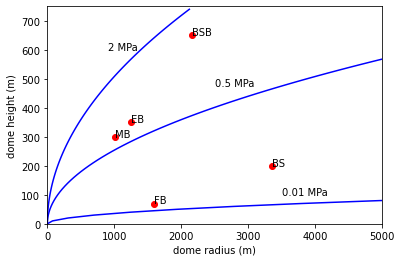

In [63]:
def calc_radius(rho_m, g, ht, c, yield_strength):
    r = rho_m*g*ht**2/(c**2 * yield_strength)
    return r

def calc_radiusL(rho_m, rho_r, conduit_length, g, c, yield_strength):
    r = rho_m*g/(c**2 * yield_strength)  * ((rho_r-rho_m)*conduit_length/rho_m)**2
    return r

#data from the ESRP on domes
diameter_long = [5.25, 2.13, 2.58, 3.26, 6.95]
diameter_short = [3.37, 1.92, 2.44, 3.1, 6.5]
height = [650, 300,350,70,200]
dome_name =["BSB", "MB", "EB", "FB", "BS"]

avg_radius = []
for i in range (len(diameter_long)):
    rad1 = diameter_long[i]/2 *1000
    rad2 = diameter_short[i]/2 *1000
    avg_radius.append((rad1+rad2)/2)

rho_m = 2400.0
rho_r = 2500
g = 10.0
c = 1.76
yield_strength1 = 2000000
yield_strength2 = 500000
yield_strength3 = 10000

calc_ht = np.arange(0,750, 10)
calc_r1 = calc_radius(rho_m, g, calc_ht, c, yield_strength1)
calc_r2 = calc_radius(rho_m, g, calc_ht, c, yield_strength2)
calc_r3 = calc_radius(rho_m, g, calc_ht, c, yield_strength3)


#if we assume no cap and rho_r = 2500, rho_m = 2400 and L between 
# 20000 and 10000 m, then max height is 
max_ht = (rho_r-rho_m)/rho_m * 10000
print("max ht = ", max_ht, "m")

#print (calc_ht**2*rho_m*g/c**2)
plt.plot(avg_radius, height, "or")
plt.plot(calc_r1, calc_ht, "b")
plt.plot(calc_r2, calc_ht, "b")
plt.plot(calc_r3, calc_ht, "b")
plt.xlim(0,5000)
plt.ylim(0,750)
plt.xlabel("dome radius (m)")
plt.ylabel("dome height (m)")

for i, txt in enumerate(dome_name):
    plt.annotate(txt, (avg_radius[i], height[i]))

plt.annotate('2 MPa', xy=(900,600))
plt.annotate('0.5 MPa', xy=(2500,475))
plt.annotate('0.01 MPa', xy=(3500,100))

plt.savefig('esrp_dome_examples.pdf')   
plt.show()

In [89]:
x = 24*1e9/4 /60/60/24/365 #year to build BSB
print(x)

190.25875190258753
